# ML Lab 4
## Name: Pranoy Mridha
## Roll No.: B_B3_36

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [12]:
df=pd.read_csv('winequality-red.csv')

In [13]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [14]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [15]:
df.shape

(1599, 12)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [17]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [18]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [19]:
df.duplicated().sum()

240

In [20]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

# Univariate Ananlysis

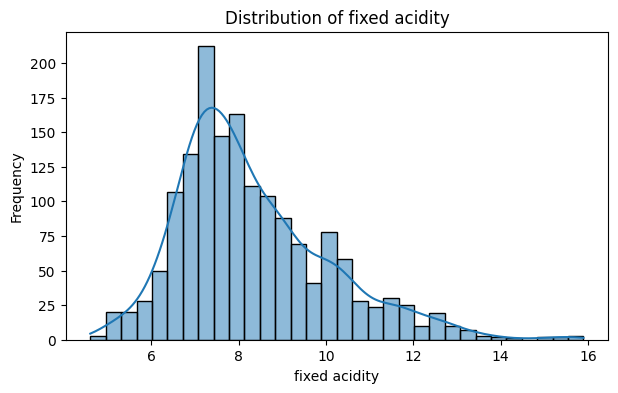

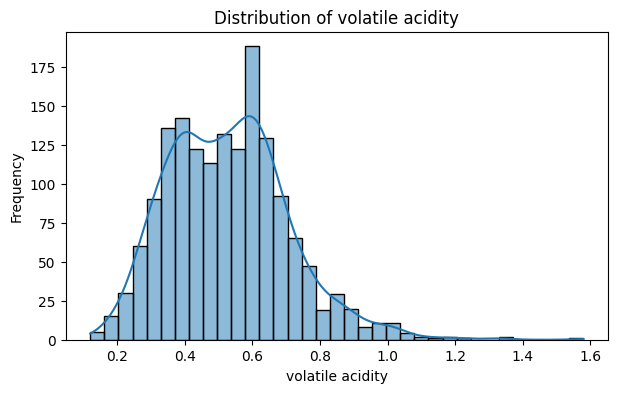

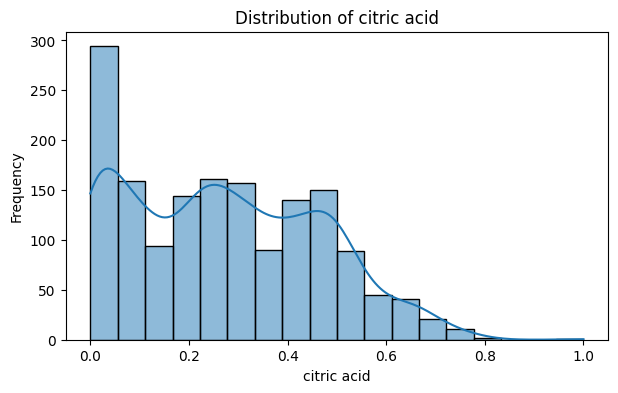

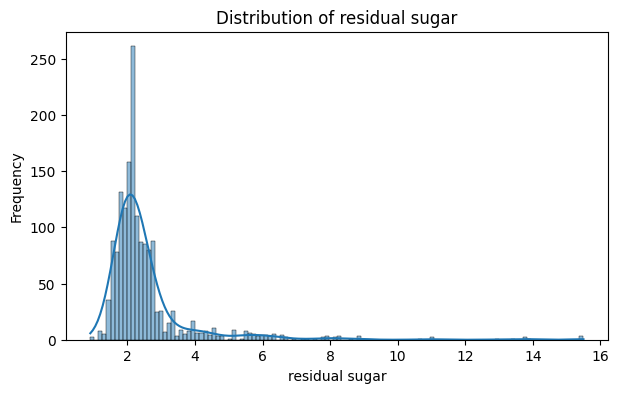

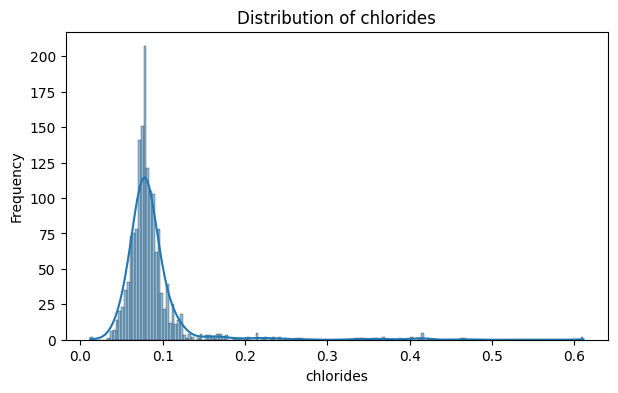

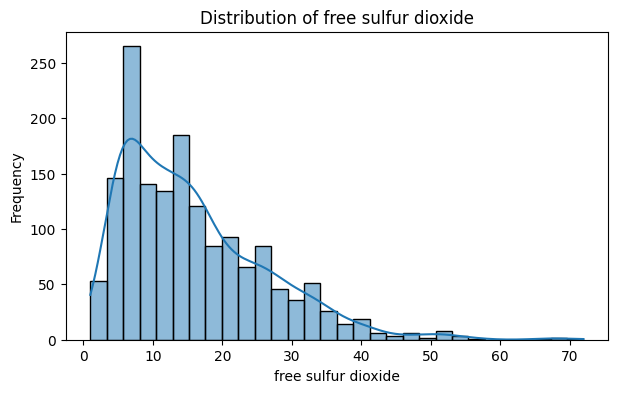

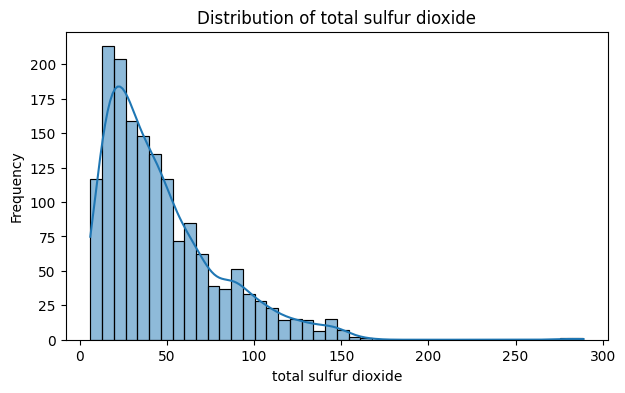

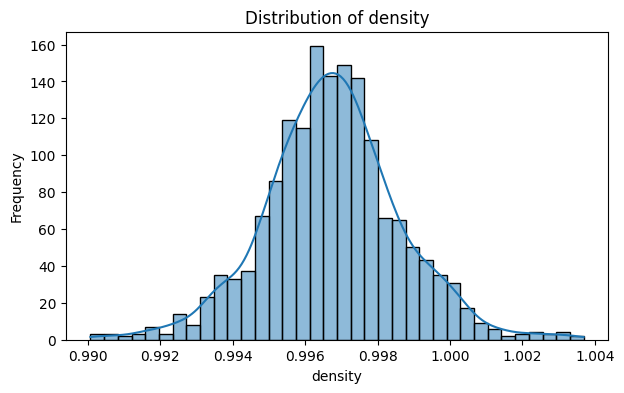

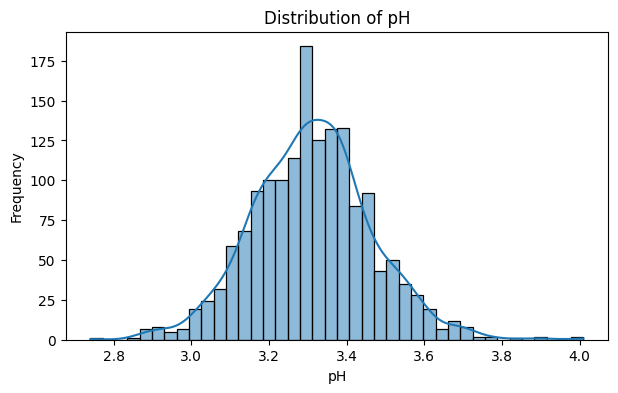

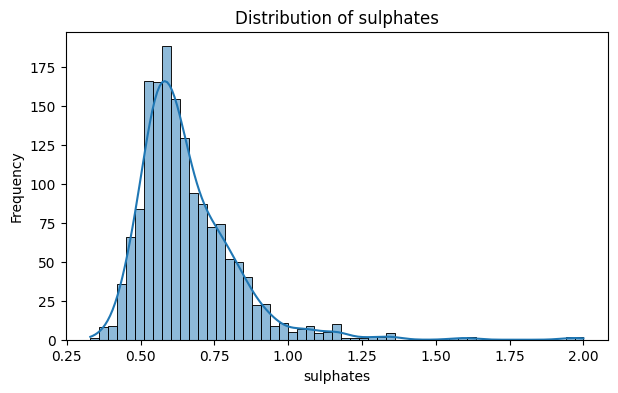

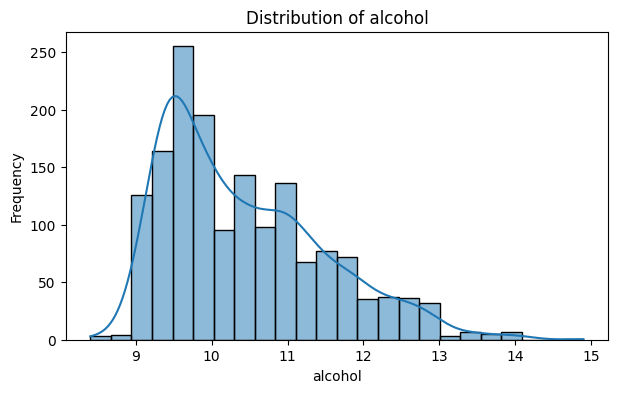

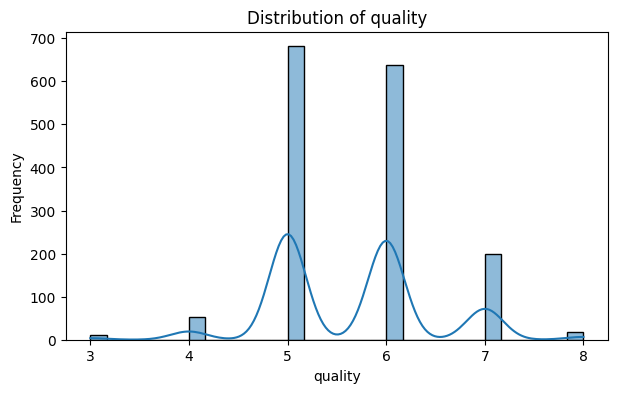

In [21]:
#Histogram+KDE
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols=df.columns

for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

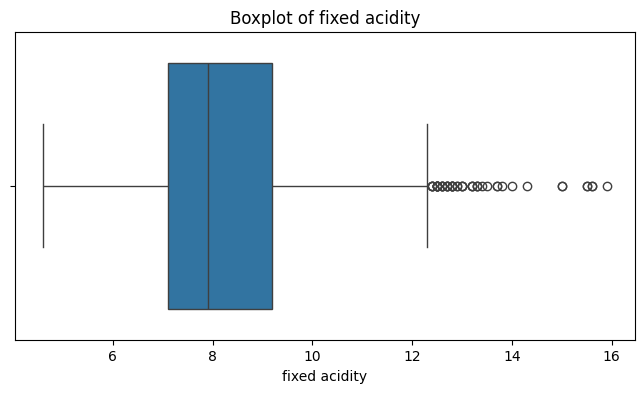

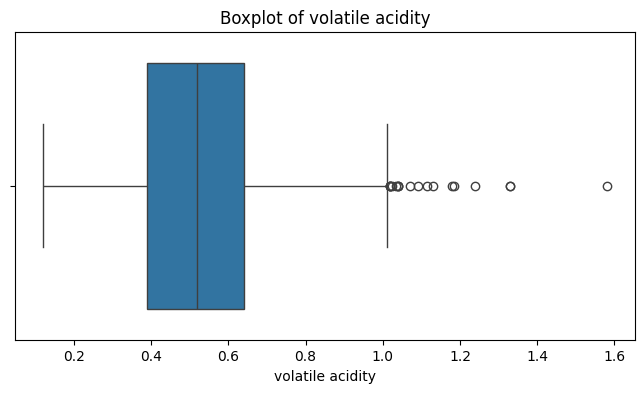

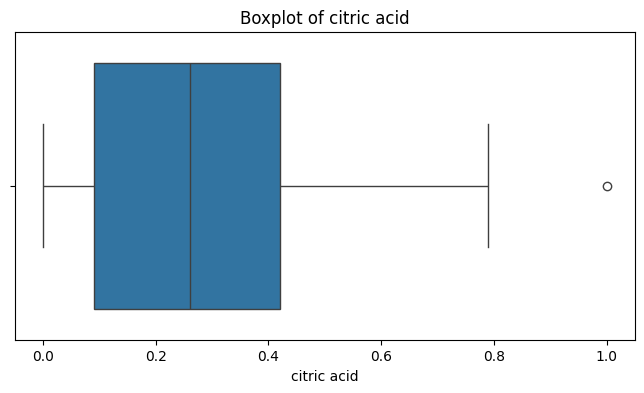

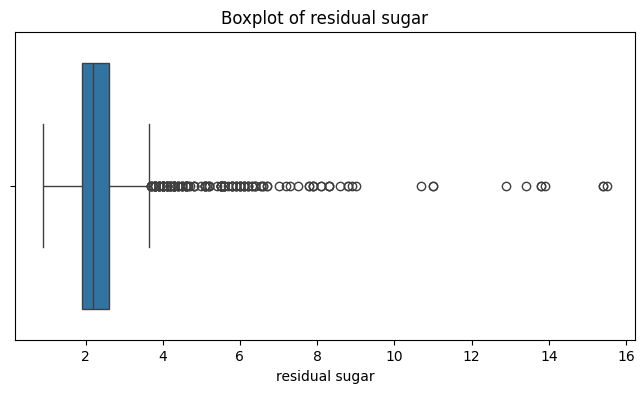

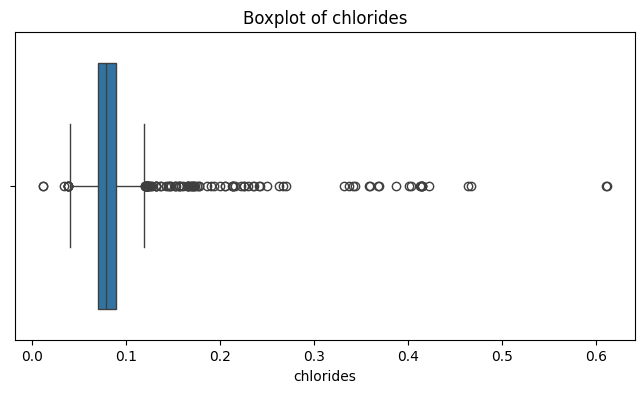

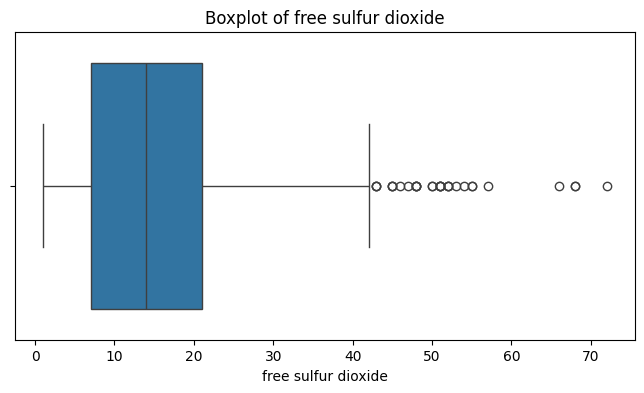

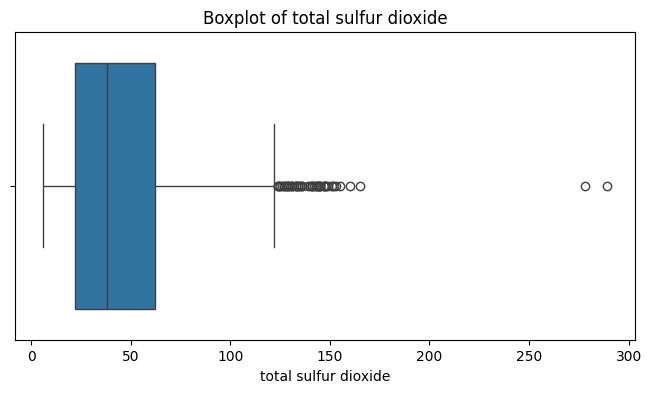

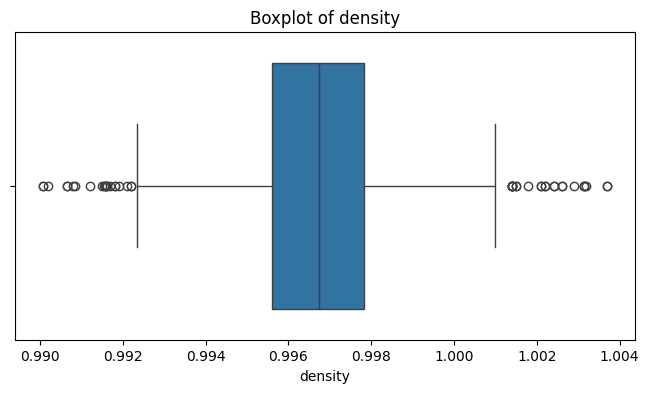

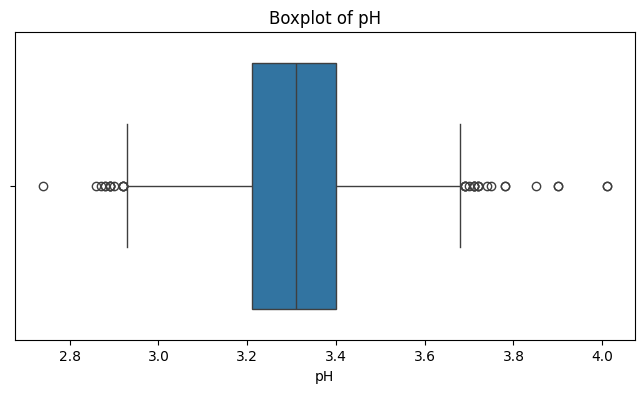

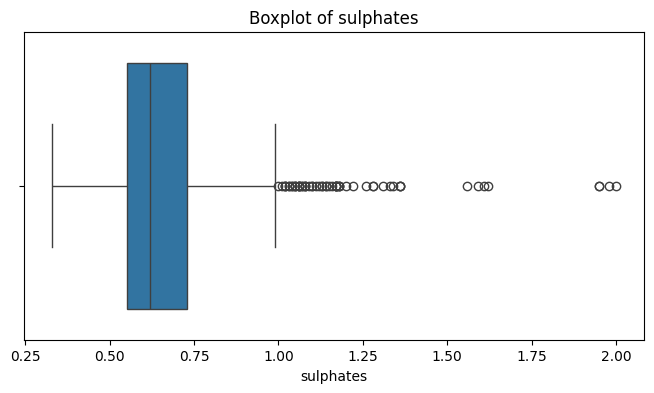

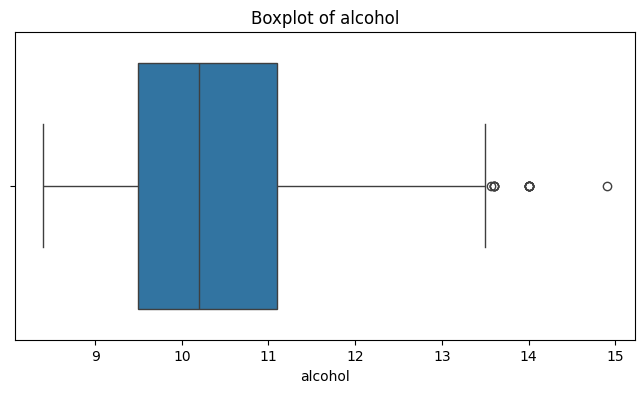

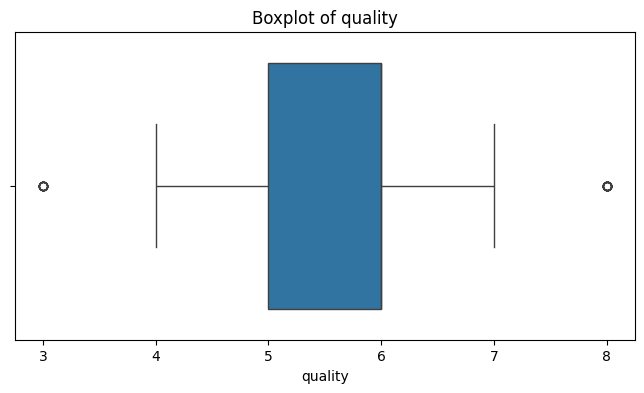

In [22]:
# Boxplot-Outlier Ananlysis
for col in numeric_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [23]:
# Detect outliers for every feature
features=df.drop(columns=["quality"])

#Calculate Q1 and Q3
Q1=features.quantile(0.25)
Q3=features.quantile(0.75)

# Calculate IQR
IQR=Q3-Q1

#Calculate Lower and Upper Limits
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

# Detect Outliers
outlier_mask=(features<lower_bound) | (features>upper_bound)

#Count outliers for each feature
outlier_count=outlier_mask.sum()

#Percentage of Outliers
outlier_percentage=(outlier_count/len(features))*100

#Create Summary table
outlier_summary=pd.DataFrame({
    'Q1':Q1,
    'Q3':Q3,
    'IQR':IQR,
    'lower bound':lower_bound,
    'upper bound':upper_bound,
    'Outlier Count':outlier_count,
    'Outlier %':outlier_percentage
})

outlier_summary.round(3)

,Q1,Q3,IQR,lower bound,upper bound,Outlier Count,Outlier %
fixed acidity,7.100,9.200,2.100,3.950,12.350,49,3.064
volatile acidity,0.390,0.640,0.250,0.015,1.015,19,1.188
citric acid,0.090,0.420,0.330,-0.405,0.915,1,0.063
residual sugar,1.900,2.600,0.700,0.850,3.650,155,9.694
chlorides,0.070,0.090,0.020,0.040,0.120,112,7.004
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,30,1.876
total sulfur dioxide,22.000,62.000,40.000,-38.000,122.000,55,3.440
density,0.996,0.998,0.002,0.992,1.001,45,2.814
pH,3.210,3.400,0.190,2.925,3.685,35,2.189
sulphates,0.550,0.730,0.180,0.280,1.000,59,3.690


In [24]:
#No of outliers in each feature

print("Outliers in each feature:\n")

for column in features.columns:
    print(f"{column:25s}:{outlier_count[column]}")

Outliers in each feature:

fixed acidity            :49
volatile acidity         :19
citric acid              :1
residual sugar           :155
chlorides                :112
free sulfur dioxide      :30
total sulfur dioxide     :55
density                  :45
pH                       :35
sulphates                :59
alcohol                  :13


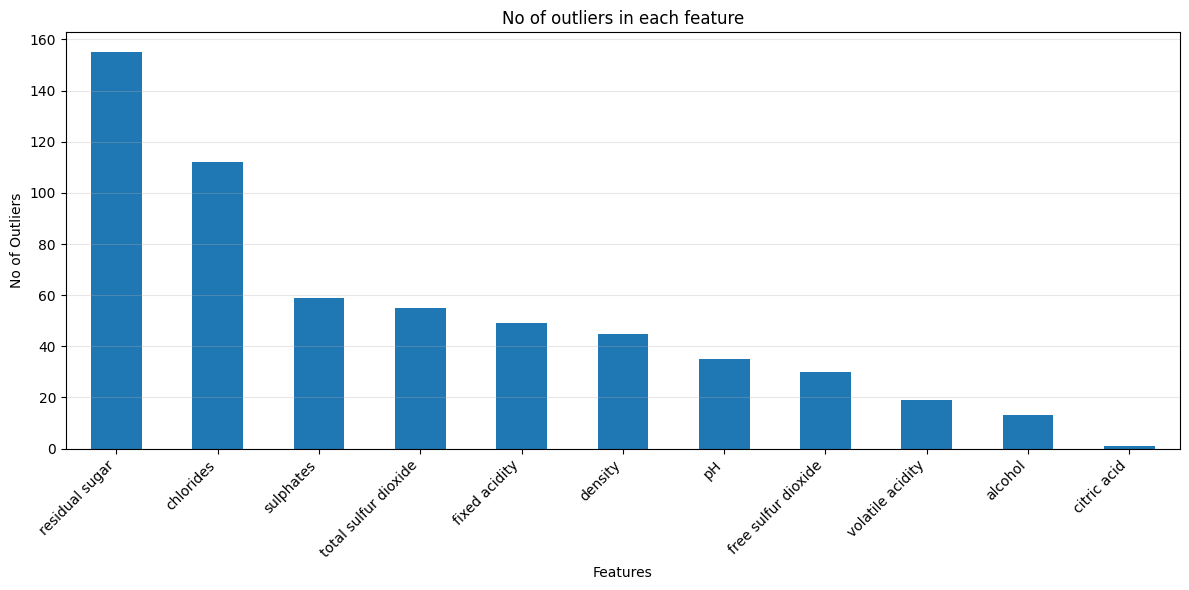

In [25]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(
    kind='bar'
)

plt.title("No of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No of Outliers")
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',alpha=0.3)

plt.tight_layout()
plt.show()

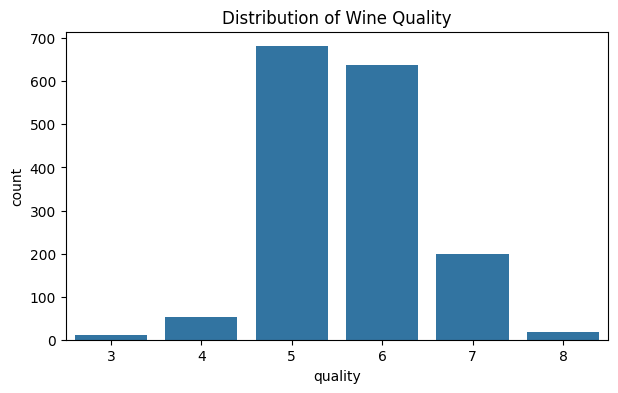

In [26]:
#Quality Distribution
plt.figure(figsize=(7,4))
sns.countplot(x='quality',data=df)
plt.title("Distribution of Wine Quality")
plt.show()

In [27]:
df['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

# 2.Bivariate Analysis

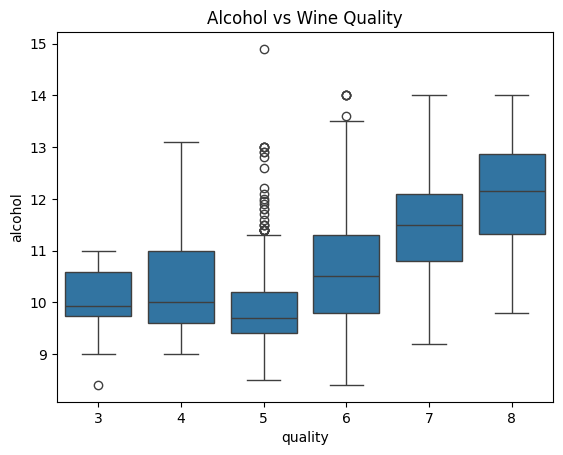

In [28]:
#Alcohol vs Quality
sns.boxplot(x='quality',y='alcohol',data=df)
plt.title('Alcohol vs Wine Quality')
plt.show()

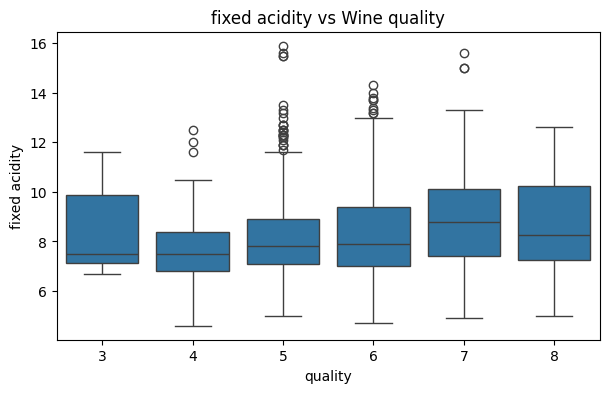

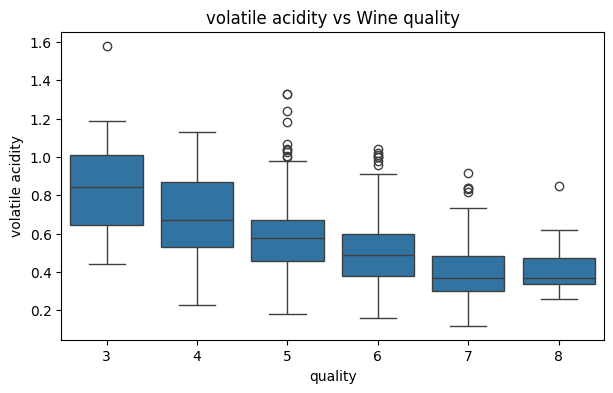

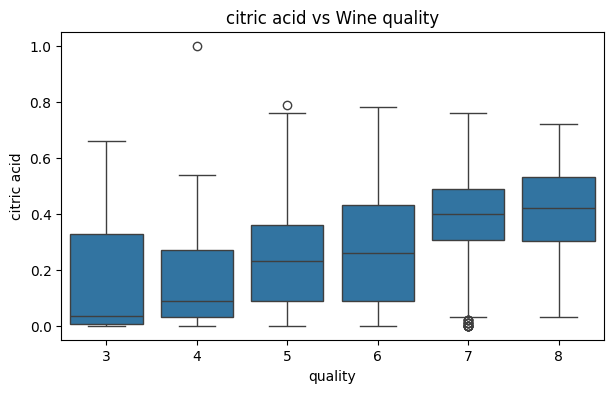

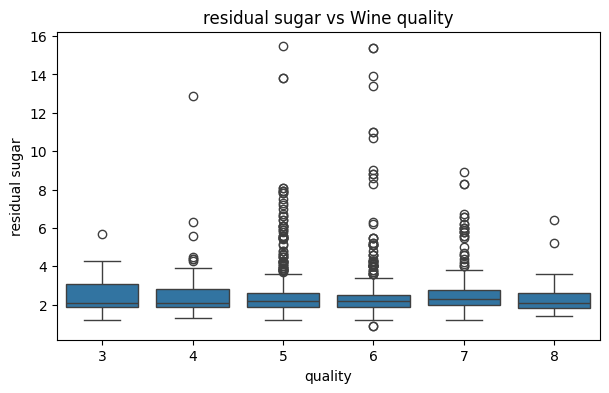

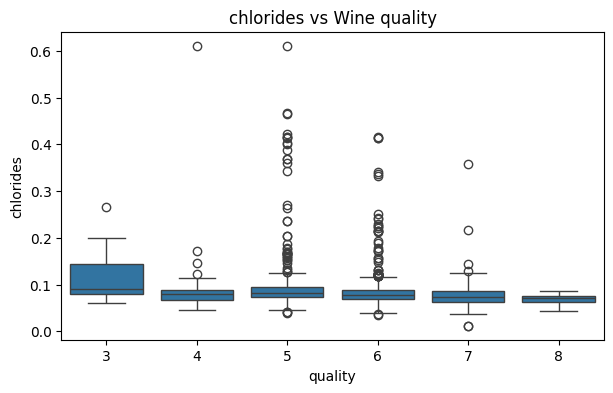

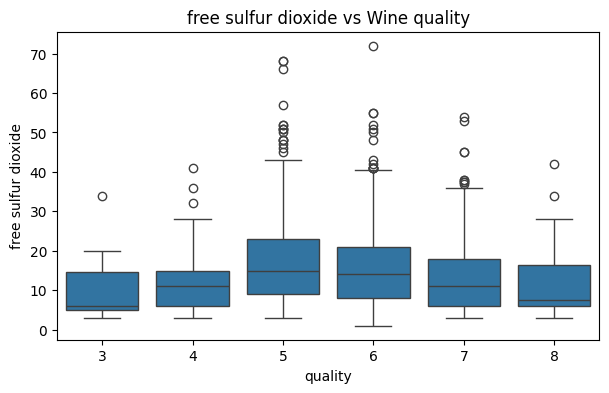

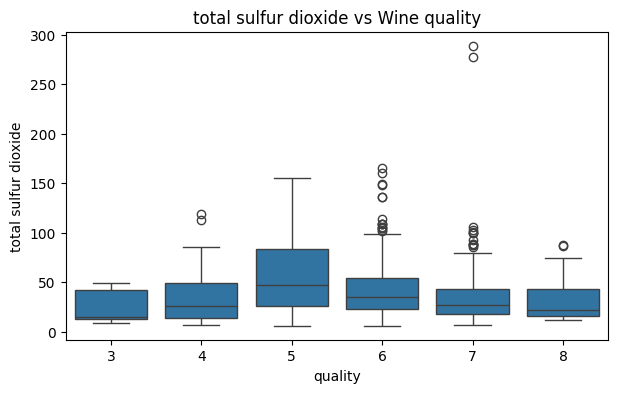

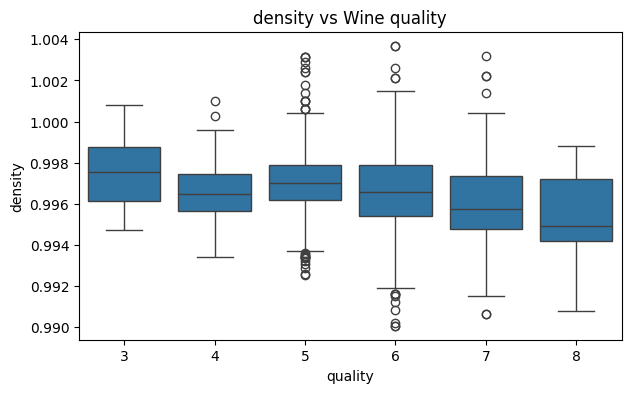

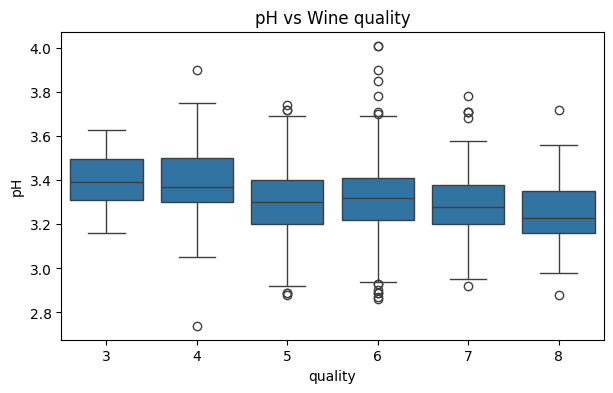

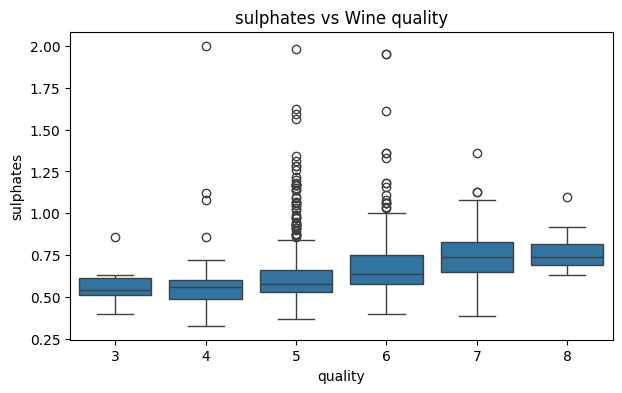

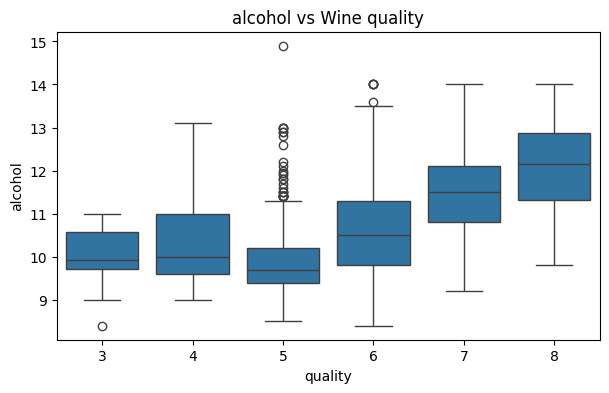

In [29]:
features=['fixed acidity','volatile acidity','citric acid','residual sugar','chlorides','free sulfur dioxide','total sulfur dioxide',
          'density','pH','sulphates','alcohol']

for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality',y=col,data=df)
    plt.title(f'{col} vs Wine quality')
    plt.show()

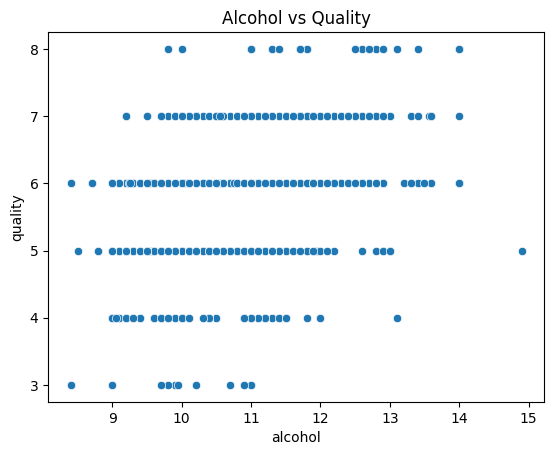

In [30]:
#Scatter Plot
sns.scatterplot(x='alcohol',y='quality',data=df)
plt.title('Alcohol vs Quality')
plt.show()

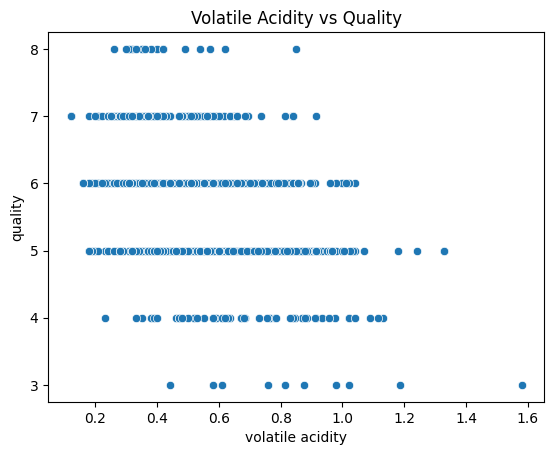

In [31]:
sns.scatterplot(x='volatile acidity',y='quality',data=df)
plt.title('Volatile Acidity vs Quality')
plt.show()

# 3.Multivariate Analysis

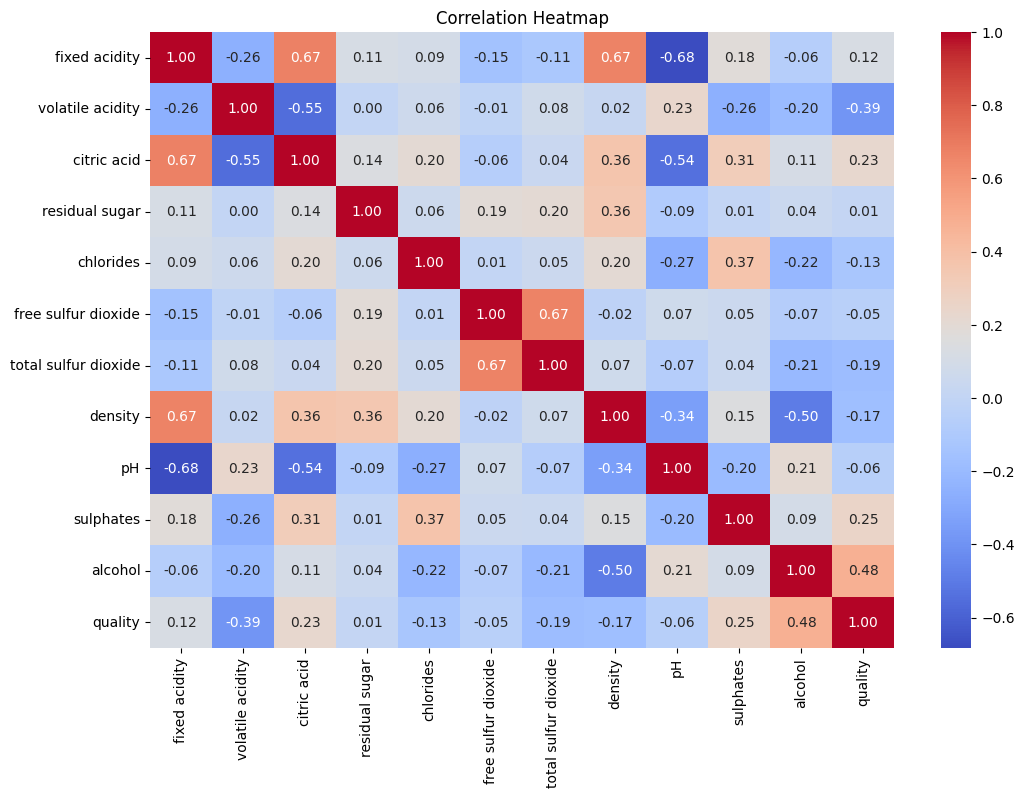

In [32]:
plt.figure(figsize=(12,8))

corr=df.corr()

sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

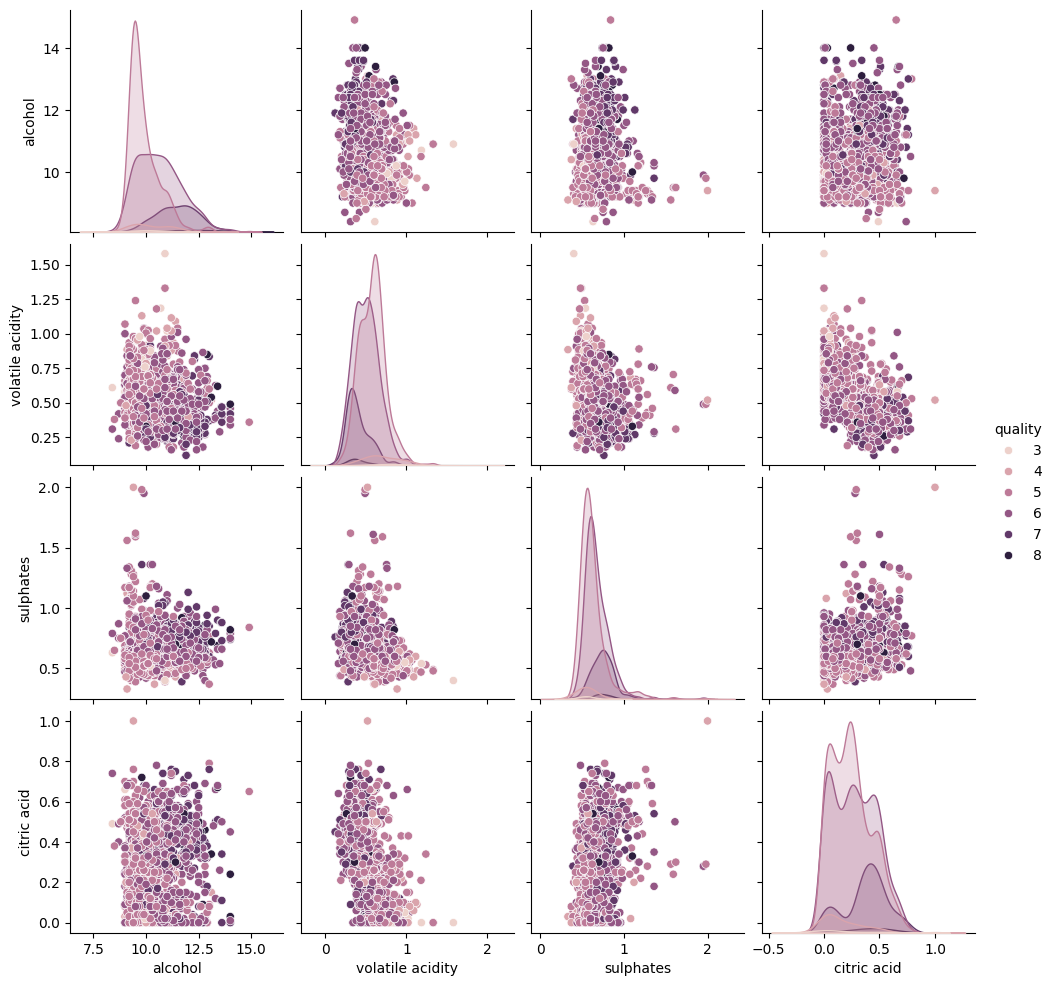

In [33]:
# Pair Plot
selected=['alcohol','volatile acidity','sulphates','citric acid','quality']

sns.pairplot(df[selected],hue='quality')

plt.show()

In [34]:
#Multivariate Ananlysis Using Quality Groups
df['quality_group']=pd.cut(
    df['quality'],
    bins=[0,5,6,10],
    labels=['Low','Medium','High']
)

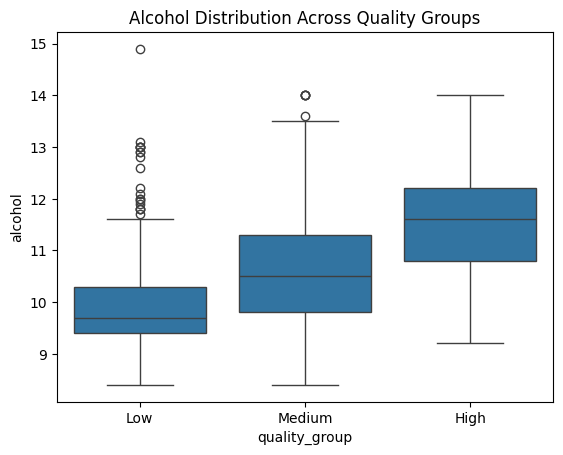

In [35]:
sns.boxplot(
    x='quality_group',
    y='alcohol',
    data=df
)

plt.title('Alcohol Distribution Across Quality Groups')
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import (accuracy_score,precision_score,recall_score,
                              f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

In [37]:
X=df.drop('quality',axis=1)
y=df['quality']

In [38]:
print(y.value_counts())

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,
                                               random_state=42,
                                               stratify=y
                                              )

In [40]:
criterion='entropy'

In [41]:
dt_model=DecisionTreeClassifier(
    criterion='entropy',
    random_state=42)

In [42]:
df['quality_group']=pd.cut(
    df['quality'],
    bins=[0,5,6,10],
    labels=['Low','Medium','High']
)

In [43]:
print(X.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality_group'],
      dtype='object')


In [44]:
print(X.select_dtypes(exclude='number').columns)

Index(['quality_group'], dtype='object')


In [45]:
y=df['quality']

In [46]:
X=df.drop(columns=['quality','quality_group'],errors='ignore')

In [47]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


In [48]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,
                                               random_state=42,
                                               stratify=y
                                              )

In [49]:
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)

dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

In [50]:
dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

In [51]:
y_train_pred=dt_model.predict(X_train)
y_test_pred=dt_model.predict(X_test)

In [52]:
train_accuracy=accuracy_score(y_train,y_train_pred)

print("Training Accuracy:",train_accuracy)

Training Accuracy: 1.0


In [53]:
test_accuracy=accuracy_score(y_test,y_test_pred)

print("Testing Accuracy:",test_accuracy)

Testing Accuracy: 0.59375


In [54]:
print("Precision:",
      precision_score(y_test,y_test_pred,average='weighted'))
print("Recall:",
      recall_score(y_test,y_test_pred,average='weighted'))
print("F1 Score:",
      f1_score(y_test,y_test_pred,average='weighted'))

Precision: 0.5899604951771574
Recall: 0.59375
F1 Score: 0.5912882260970955


In [55]:
print(classification_report(y_test,y_test_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.11      0.09      0.10        11
           5       0.66      0.64      0.65       136
           6       0.58      0.62      0.60       128
           7       0.53      0.53      0.53        40
           8       0.50      0.33      0.40         3

    accuracy                           0.59       320
   macro avg       0.40      0.37      0.38       320
weighted avg       0.59      0.59      0.59       320



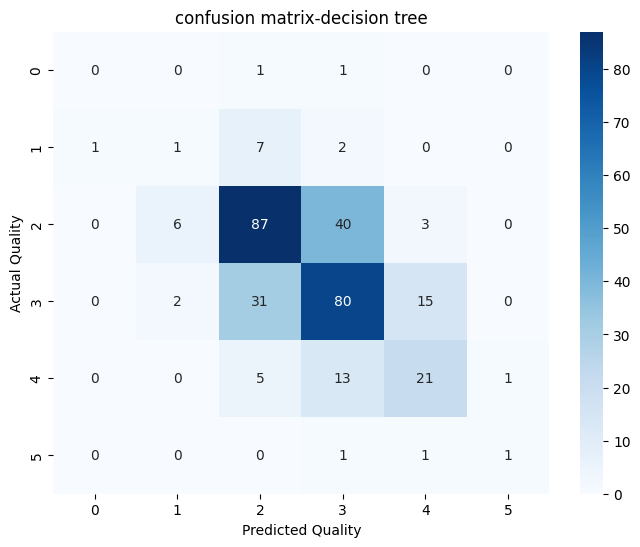

In [56]:
cm=confusion_matrix(y_test,y_test_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.title('confusion matrix-decision tree')

plt.show()

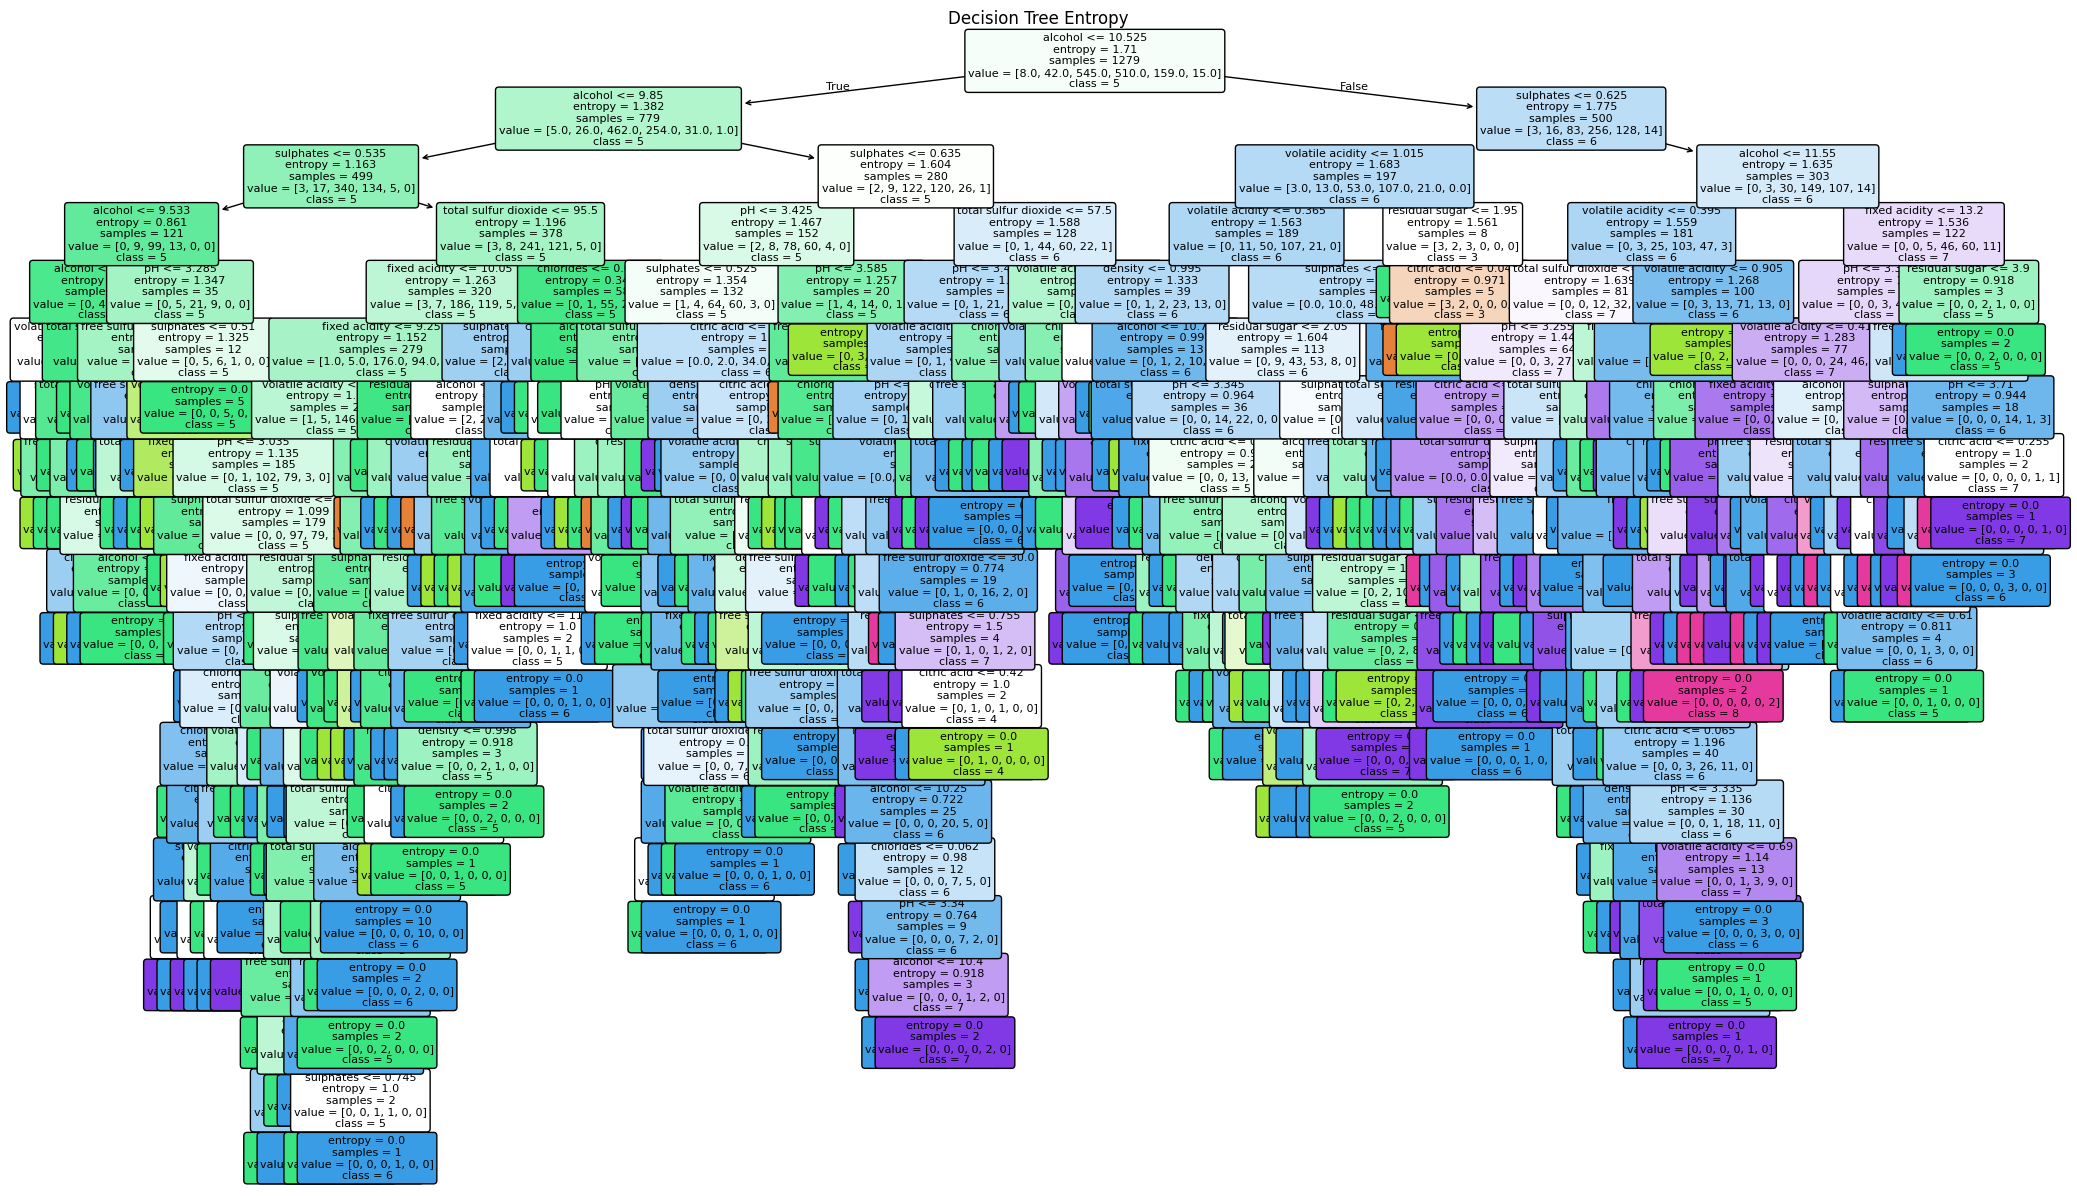

In [59]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 15))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Entropy")
plt.show()

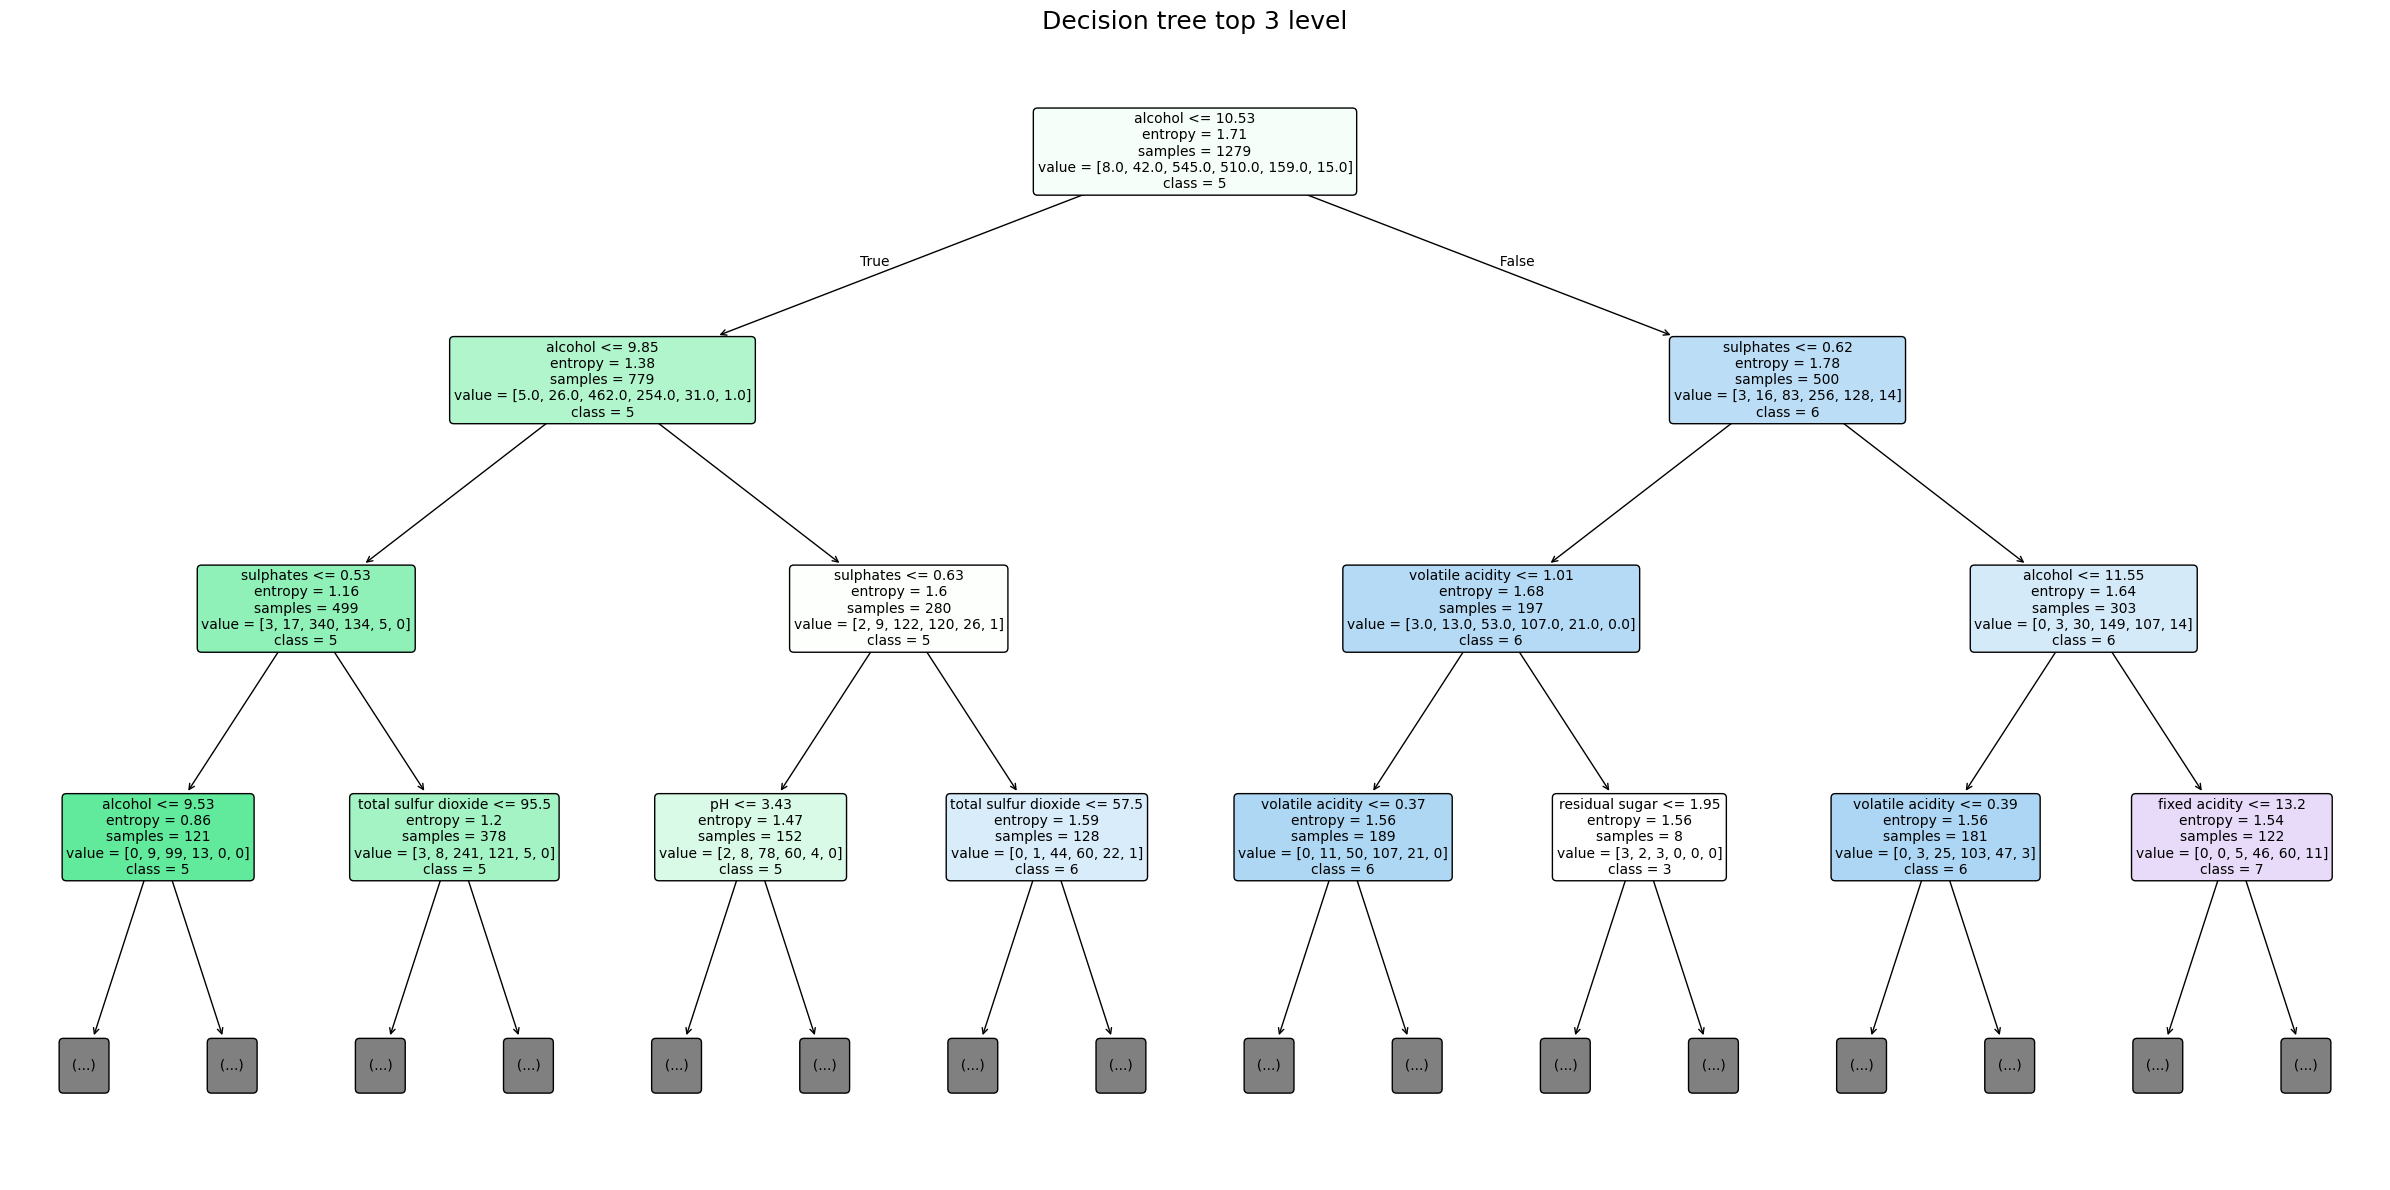

In [60]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    impurity=True,
    precision=2,
    fontsize=10,max_depth=3
)

plt.title("Decision tree top 3 level" ,fontsize=18)
plt.tight_layout()
plt.show()

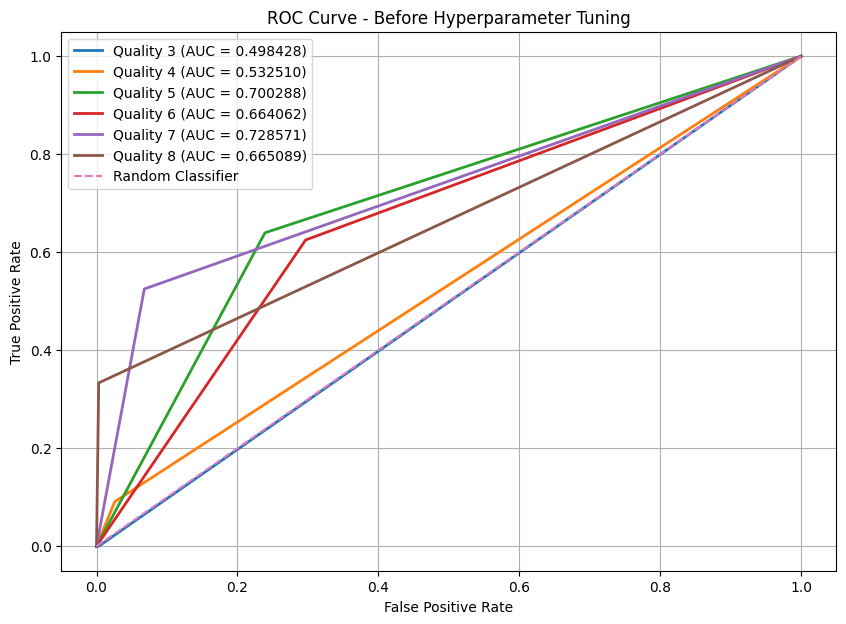

Overall ROC-AUC Before Tuning: 0.682


In [62]:
# ROC Curve and AOC - Before HYPRERPARAMETER TUNING

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

#get unique classes
classes = sorted(y_test.unique())

#convert y_test to binary format
y_test_bin = label_binarize(y_test, classes=classes)

#Get probability predictions
y_score = dt_model.predict_proba(X_test)

#Plot ROC Curve
plt.figure(figsize = (10,7))

for i, class_label in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label = f'Quality {class_label} (AUC = {roc_auc:2f})')

#Random Classifier
plt.plot([0,1],[0,1], linestyle = '--', label = "Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Before Hyperparameter Tuning")

plt.legend()
plt.grid()
plt.show()

#Overall AUC
overall_auc_before = roc_auc_score(y_test_bin, y_score, multi_class = 'ovr',
                                  average = 'weighted')

print("Overall ROC-AUC Before Tuning:", round(overall_auc_before, 4))

### Hyperparameter Tuning

In [67]:
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')

param_grid = {
    'criterion':['entropy'],
    'max_depth':[3,5,7,10,None],
    'min_samples_split':[2,5,10,20],
    'min_samples_leaf':[1,2,4,8],
    'max_features':[None,'sqrt','log2'],
    'ccp_alpha':[0,0.001,0.005,0.01]
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5,scoring='accuracy', n_jobs=-1)

grid.fit(X_train, y_train)

print("Best Parameters")
print(grid.best_params_)

print("Best Cross Validation Accuracy")
print(grid.best_score_)

best_tree = grid.best_estimator_

Best Parameters
{'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross Validation Accuracy
0.6012500000000001


In [68]:
y_pred = best_tree.predict(X_test)

print(classification_report(y_test, y_pred))
print("Accuracy =", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.62      0.62       136
           6       0.56      0.55      0.56       128
           7       0.46      0.53      0.49        40
           8       0.00      0.00      0.00         3

    accuracy                           0.55       320
   macro avg       0.27      0.28      0.28       320
weighted avg       0.55      0.55      0.55       320

Accuracy = 0.546875


In [69]:
#Training Accuracy
train_accuracy = best_tree.score(X_train, y_train)

#Testing Accuracy
test_accuracy = best_tree.score(X_test, y_test)

print("Training Accuracy =", train_accuracy)
print("Testing Accuracy =", test_accuracy)

Training Accuracy = 0.8577013291634089
Testing Accuracy = 0.546875


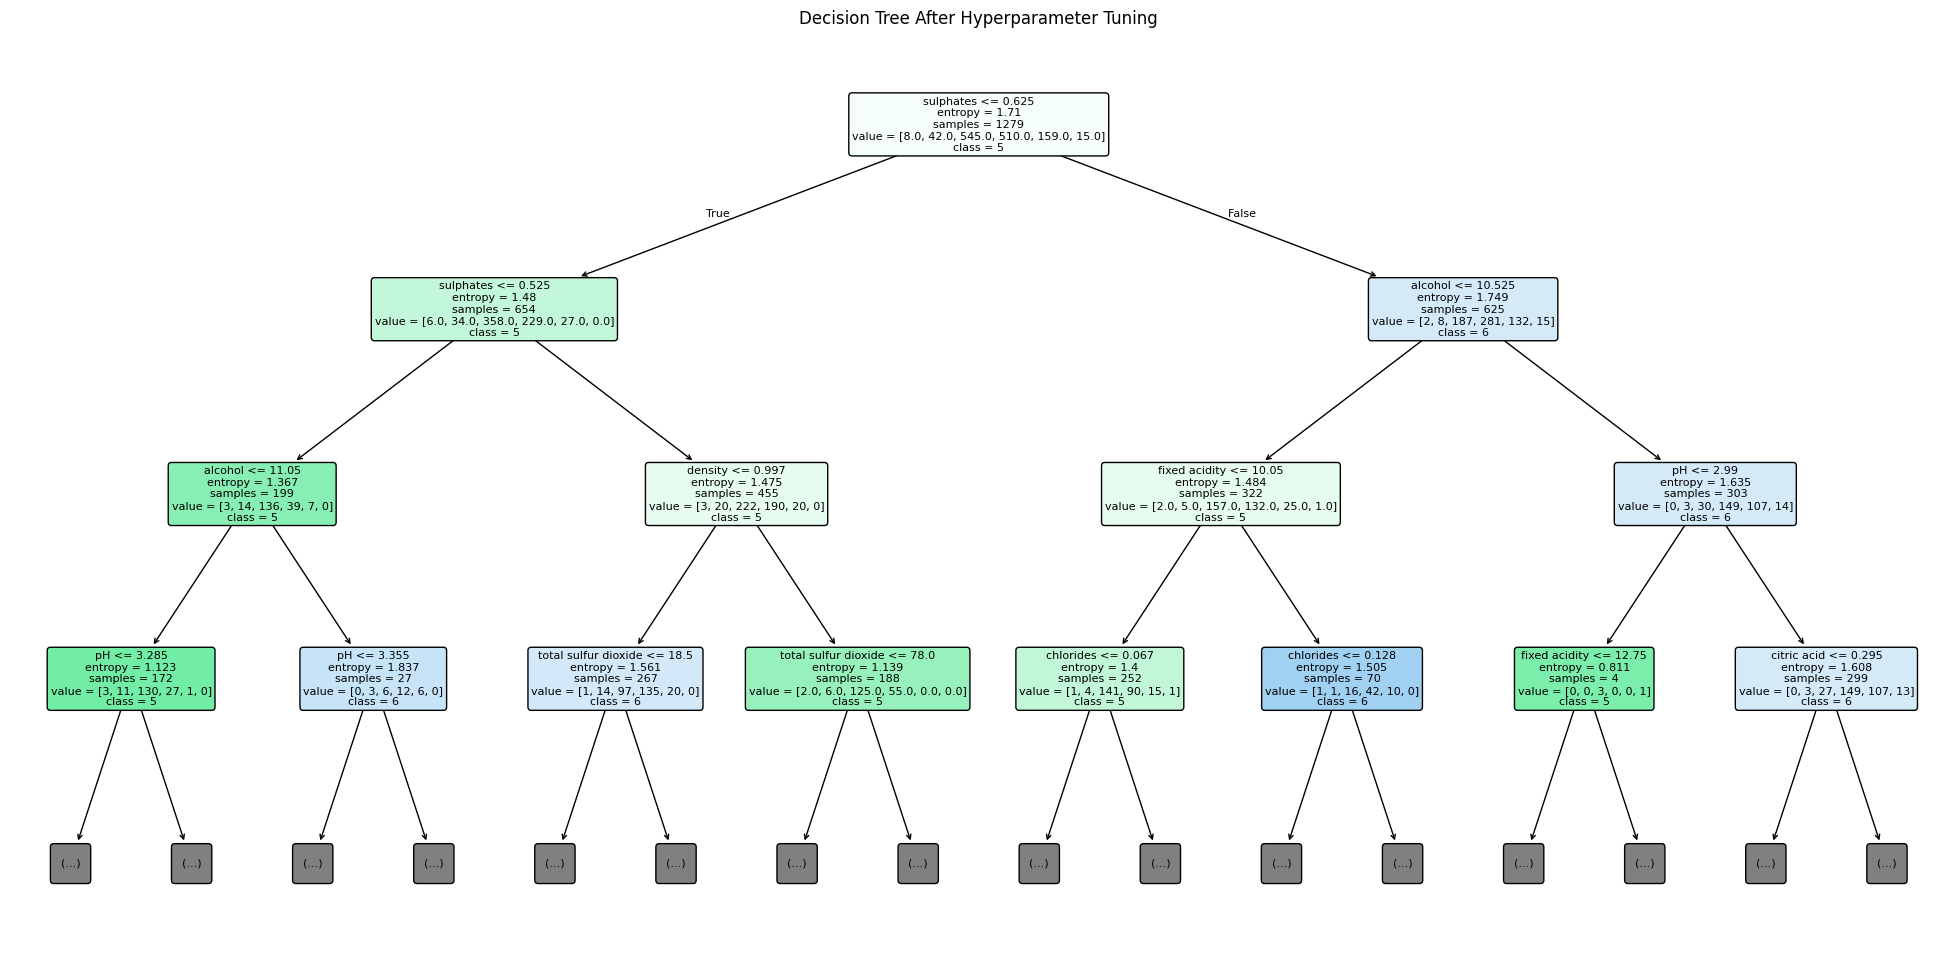

In [77]:
plt.figure(figsize=(25, 12))

plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=[str(c) for c in best_tree.classes_],
    filled=True,
    rounded=True,
    max_depth = 3,
    fontsize=8,
)

plt.title("Decision Tree After Hyperparameter Tuning")
plt.show()

### Cross Validation

In [79]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(best_tree, X, y, cv = 10, scoring = 'accuracy')

print(scores)

print("Average Accuracy =", scores.mean())

print("Std =", scores.std())

[0.525      0.5625     0.41875    0.475      0.4875     0.5375
 0.4625     0.4625     0.50625    0.46540881]
Average Accuracy = 0.4902908805031447
Std = 0.040528700639559496


### Learning Curve

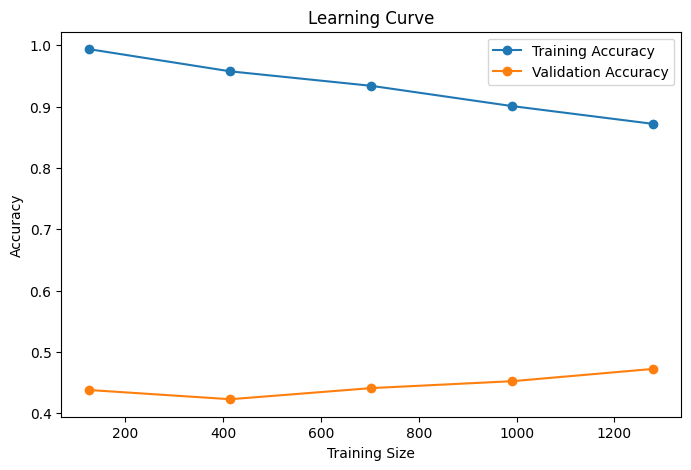

In [81]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(best_tree, X, y, cv = 5, scoring = 'accuracy')

plt.figure(figsize = (8,5))

plt.plot(train_sizes, train_scores.mean(axis = 1), marker = 'o', label = 'Training Accuracy')

plt.plot(train_sizes, test_scores.mean(axis=1), marker = 'o', label = "Validation Accuracy")

plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")

plt.legend()
plt.show()

In [93]:
new_wine = pd.DataFrame([{
    'fixed acidity': 7.0,
    'volatile acidity': 0.50,
    "citric acid": 0.20,
    "residual sugar": 2.0,
    'chlorides': 0.070,
    'free sulfur dioxide': 15.0,
    'total sulfur dioxide': 40.0,
    "density": 0.995,
    'pH': 3.30,
    'sulphates': 0.60,
    'alcohol': 10.0
}])

prediction = best_tree.predict(new_wine)

print("Predicted Wine Quality: ", prediction[0])

Predicted Wine Quality:  5


In [94]:
probability = best_tree.predict_proba(new_wine)

print("Predicted Quality: ", prediction[0])
print("Probabilities: ", probability)

Predicted Quality:  5
Probabilities:  [[0.         0.02857143 0.48571429 0.48571429 0.         0.        ]]
